# Project Initialization and Exploratory Data Analysis
We will start by importing the necessary libraries and loading the datasets to understand their structure.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train_df = pd.read_csv('/content/train.csv')
test_df = pd.read_csv('/content/test.csv')
submission_df = pd.read_csv('/content/sample_submission.csv')

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Submission shape:", submission_df.shape)

Train shape: (200000, 16)
Test shape: (50000, 15)
Submission shape: (50000, 2)


In [2]:
print("--- Train Info ---")
display(train_df.info())
print("\n--- First 5 Rows of Train Dataset ---")
display(train_df.head())

--- Train Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 16 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   customer_age            200000 non-null  int64  
 1   product_price           200000 non-null  float64
 2   discount_percent        200000 non-null  float64
 3   product_rating          200000 non-null  float64
 4   past_purchase_count     200000 non-null  int64  
 5   past_return_rate        200000 non-null  float64
 6   delivery_delay_days     200000 non-null  float64
 7   session_length_minutes  200000 non-null  float64
 8   num_product_views       200000 non-null  int64  
 9   device_type             200000 non-null  object 
 10  product_category        200000 non-null  object 
 11  shipping_method         200000 non-null  object 
 12  payment_method          200000 non-null  object 
 13  used_coupon             200000 non-null  int64  
 14  r

None


--- First 5 Rows of Train Dataset ---


,customer_age,product_price,discount_percent,product_rating,past_purchase_count,past_return_rate,delivery_delay_days,session_length_minutes,num_product_views,device_type,product_category,shipping_method,payment_method,used_coupon,returned,order_id
0,25,11.666137,43.559601,1.933533,8,0.331408,-0.089637,3.273029,26,tablet,sports,express,paypal,1,0,75381
1,76,31.378967,66.526039,0.690237,9,0.105203,3.639277,130.513123,8,mobile,electronics,standard,credit_card,1,0,65569
2,40,25.460603,20.762374,2.347620,14,0.236683,0.294060,92.780917,-2,desktop,toys,express,credit_card,0,0,163473
3,62,13.517170,25.669260,2.033596,9,0.410038,1.683333,103.004177,7,mobile,clothing,express,apple_pay,0,0,90518
4,51,75.771311,15.527927,4.907556,9,0.123565,-0.153691,100.752658,6,mobile,electronics,standard,credit_card,1,0,138866


# Model Training and Prediction
We will preprocess the features, train a LightGBM classifier, and write predictions to the sample submission file.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import roc_auc_score, accuracy_score
import lightgbm as lgb

# Prepare features
features = [
    'customer_age', 'product_price', 'discount_percent', 'product_rating',
    'past_purchase_count', 'past_return_rate', 'delivery_delay_days',
    'session_length_minutes', 'num_product_views', 'device_type',
    'product_category', 'shipping_method', 'payment_method', 'used_coupon'
]

X = train_df[features].copy()
y = train_df['returned'].copy()
X_test = test_df[features].copy()

# Encode categorical variables
cat_cols = ['device_type', 'product_category', 'shipping_method', 'payment_method']
for col in cat_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    X_test[col] = le.transform(X_test[col].astype(str))

# Train/Validation Split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Train LightGBM Model
model = lgb.LGBMClassifier(
    n_estimators=100,
    learning_rate=0.05,
    random_state=42,
    n_jobs=-1
)

model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(stopping_rounds=10, verbose=False)]
)

# Evaluate Model
val_preds = model.predict_proba(X_val)[:, 1]
val_class_preds = model.predict(X_val)
auc_score = roc_auc_score(y_val, val_preds)
acc_score = accuracy_score(y_val, val_class_preds)
print(f"Validation ROC AUC: {auc_score:.4f}")
print(f"Validation Accuracy: {acc_score:.4f}")

[LightGBM] [Info] Number of positive: 75935, number of negative: 84065
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.020170 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1704
[LightGBM] [Info] Number of data points in the train set: 160000, number of used features: 14
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.474594 -> initscore=-0.101713
[LightGBM] [Info] Start training from score -0.101713
Validation ROC AUC: 0.5954
Validation Accuracy: 0.5723


In [4]:
# Generate predictions on the test set
test_preds = model.predict(X_test)

# Prepare submission file
submission_df['returned'] = test_preds
submission_df.to_csv('submission.csv', index=False)
print("Submission file 'submission.csv' generated successfully!")
print(submission_df.head())

Submission file 'submission.csv' generated successfully!
       ID  returned
0   38683         1
1   64939         0
2    3954         0
3  120374         1
4  172861         0


# Advanced Feature Engineering and Optimized Modeling
Let's clean potential anomalies (e.g., negative product views, negative prices, or negative delivery delays) and train an optimized model to improve predictive quality.

In [5]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import roc_auc_score, accuracy_score
import lightgbm as lgb

# Load fresh copies of data
train_clean = pd.read_csv('/content/train.csv')
test_clean = pd.read_csv('/content/test.csv')

# Correct anomalies (e.g., negative views, negative delays, negative prices)
for df in [train_clean, test_clean]:
    df['num_product_views'] = df['num_product_views'].clip(lower=0)
    df['delivery_delay_days'] = df['delivery_delay_days'].clip(lower=0)
    df['product_price'] = df['product_price'].clip(lower=0)
    df['discount_percent'] = df['discount_percent'].clip(0, 100)

# Basic engineered features
for df in [train_clean, test_clean]:
    df['discount_amount'] = df['product_price'] * (df['discount_percent'] / 100.0)
    df['final_price'] = df['product_price'] - df['discount_amount']
    df['views_per_age'] = df['num_product_views'] / (df['customer_age'] + 1)

features = [
    'customer_age', 'product_price', 'discount_percent', 'product_rating',
    'past_purchase_count', 'past_return_rate', 'delivery_delay_days',
    'session_length_minutes', 'num_product_views', 'device_type',
    'product_category', 'shipping_method', 'payment_method', 'used_coupon',
    'discount_amount', 'final_price', 'views_per_age'
]

X = train_clean[features].copy()
y = train_clean['returned'].copy()
X_test = test_clean[features].copy()

# Categorical encoding
cat_cols = ['device_type', 'product_category', 'shipping_method', 'payment_method']
for col in cat_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    X_test[col] = le.transform(X_test[col].astype(str))

# 5-Fold Cross Validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_preds = np.zeros(len(X))
test_preds_fold = np.zeros(len(X_test))

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]

    model = lgb.LGBMClassifier(
        n_estimators=150,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42 + fold,
        n_jobs=-1,
        verbose=-1
    )

    model.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        callbacks=[lgb.early_stopping(stopping_rounds=15, verbose=False)]
    )

    oof_preds[val_idx] = model.predict_proba(X_va)[:, 1]
    test_preds_fold += model.predict_proba(X_test)[:, 1] / skf.n_splits

print(f"OOF ROC AUC Score: {roc_auc_score(y, oof_preds):.4f}")

# Generate final binary predictions
final_predictions = (test_preds_fold >= 0.5).astype(int)
submission_df['returned'] = final_predictions
submission_df.to_csv('/content/submission.csv', index=False)
print("Optimized submission.csv generated and saved!")
display(submission_df.head())

OOF ROC AUC Score: 0.5941
Optimized submission.csv generated and saved!


,ID,returned
0,38683,1
1,64939,0
2,3954,0
3,120374,1
4,172861,0


## Round 2: Enhanced Feature Engineering and Tuning
In this step, we will design more advanced domain features and refine our modeling configuration to maximize predictive accuracy.

In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import roc_auc_score
import lightgbm as lgb

# Load fresh copies
train_rnd2 = pd.read_csv('/content/train.csv')
ttest_rnd2 = pd.read_csv('/content/test.csv')

# Clip outliers/anomalies
for df in [train_rnd2, ttest_rnd2]:
    df['num_product_views'] = df['num_product_views'].clip(lower=0)
    df['delivery_delay_days'] = df['delivery_delay_days'].clip(lower=0)
    df['product_price'] = df['product_price'].clip(lower=0)
    df['discount_percent'] = df['discount_percent'].clip(0, 100)

# Advanced interactions
for df in [train_rnd2, ttest_rnd2]:
    df['discount_amount'] = df['product_price'] * (df['discount_percent'] / 100.0)
    df['final_price'] = df['product_price'] - df['discount_amount']
    df['views_per_age'] = df['num_product_views'] / (df['customer_age'] + 1)
    df['price_per_view'] = df['product_price'] / (df['num_product_views'] + 1)
    df['delivery_per_price'] = df['delivery_delay_days'] / (df['product_price'] + 1)

# Target encoding simulation using out-of-fold category averages or frequency encoding
for col in ['device_type', 'product_category', 'shipping_method', 'payment_method']:
    freq = train_rnd2[col].value_counts().to_dict()
    train_rnd2[f'{col}_freq'] = train_rnd2[col].map(freq)
    ttest_rnd2[f'{col}_freq'] = ttest_rnd2[col].map(freq).fillna(0)

features = [
    'customer_age', 'product_price', 'discount_percent', 'product_rating',
    'past_purchase_count', 'past_return_rate', 'delivery_delay_days',
    'session_length_minutes', 'num_product_views', 'device_type',
    'product_category', 'shipping_method', 'payment_method', 'used_coupon',
    'discount_amount', 'final_price', 'views_per_age', 'price_per_view',
    'delivery_per_price', 'device_type_freq', 'product_category_freq',
    'shipping_method_freq', 'payment_method_freq'
]

X = train_rnd2[features].copy()
y = train_rnd2['returned'].copy()
X_test = ttest_rnd2[features].copy()

# Label encoding for remaining categoricals
cat_cols = ['device_type', 'product_category', 'shipping_method', 'payment_method']
for col in cat_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    X_test[col] = le.transform(X_test[col].astype(str))

# 5-Fold Stratified CV with hyperparameter fine-tuning
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=101)
oof_preds = np.zeros(len(X))
test_preds_fold = np.zeros(len(X_test))

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]

    model = lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.03,
        num_leaves=63,
        max_depth=8,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=101 + fold,
        n_jobs=-1,
        verbose=-1
    )

    model.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        callbacks=[lgb.early_stopping(stopping_rounds=20, verbose=False)]
    )

    oof_preds[val_idx] = model.predict_proba(X_va)[:, 1]
    test_preds_fold += model.predict_proba(X_test)[:, 1] / skf.n_splits

print(f"Round 2 OOF ROC AUC: {roc_auc_score(y, oof_preds):.4f}")

# Finalize and export predictions
final_predictions = (test_preds_fold >= 0.5).astype(int)
submission_df['returned'] = final_predictions
submission_df.to_csv('/content/submission.csv', index=False)
print("Round 2 optimized predictions exported successfully to 'submission.csv'!")

Round 2 OOF ROC AUC: 0.5944
Round 2 optimized predictions exported successfully to 'submission.csv'!


## Round 3: Multi-Model Ensemble (LightGBM + CatBoost)
We will train both LightGBM and CatBoost using our advanced engineered features, then combine their prediction probabilities to form the final submission.

In [7]:
!pip install catboost -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.4 MB/s eta 0:00:00


In [8]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import roc_auc_score
import lightgbm as lgb
from catboost import CatBoostClassifier

# Load fresh copies of our data
train_rnd3 = pd.read_csv('/content/train.csv')
ttest_rnd3 = pd.read_csv('/content/test.csv')

# Standardize outliers/anomalies
for df in [train_rnd3, ttest_rnd3]:
    df['num_product_views'] = df['num_product_views'].clip(lower=0)
    df['delivery_delay_days'] = df['delivery_delay_days'].clip(lower=0)
    df['product_price'] = df['product_price'].clip(lower=0)
    df['discount_percent'] = df['discount_percent'].clip(0, 100)

# Advanced interactions
for df in [train_rnd3, ttest_rnd3]:
    df['discount_amount'] = df['product_price'] * (df['discount_percent'] / 100.0)
    df['final_price'] = df['product_price'] - df['discount_amount']
    df['views_per_age'] = df['num_product_views'] / (df['customer_age'] + 1)
    df['price_per_view'] = df['product_price'] / (df['num_product_views'] + 1)
    df['delivery_per_price'] = df['delivery_delay_days'] / (df['product_price'] + 1)

# Frequency encoding for categorical columns
for col in ['device_type', 'product_category', 'shipping_method', 'payment_method']:
    freq = train_rnd3[col].value_counts().to_dict()
    train_rnd3[f'{col}_freq'] = train_rnd3[col].map(freq)
    ttest_rnd3[f'{col}_freq'] = ttest_rnd3[col].map(freq).fillna(0)

features = [
    'customer_age', 'product_price', 'discount_percent', 'product_rating',
    'past_purchase_count', 'past_return_rate', 'delivery_delay_days',
    'session_length_minutes', 'num_product_views', 'device_type',
    'product_category', 'shipping_method', 'payment_method', 'used_coupon',
    'discount_amount', 'final_price', 'views_per_age', 'price_per_view',
    'delivery_per_price', 'device_type_freq', 'product_category_freq',
    'shipping_method_freq', 'payment_method_freq'
]

X = train_rnd3[features].copy()
y = train_rnd3['returned'].copy()
X_test = ttest_rnd3[features].copy()

# Encode categorical string columns
cat_cols = ['device_type', 'product_category', 'shipping_method', 'payment_method']
for col in cat_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    X_test[col] = le.transform(X_test[col].astype(str))

# Initialize cross-validation structures
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=2023)
oof_lgb = np.zeros(len(X))
oof_cat = np.zeros(len(X))
test_lgb = np.zeros(len(X_test))
test_cat = np.zeros(len(X_test))

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]

    # LightGBM Classifier
    model_lgb = lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.03,
        num_leaves=63,
        max_depth=8,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=2023 + fold,
        n_jobs=-1,
        verbose=-1
    )
    model_lgb.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        callbacks=[lgb.early_stopping(stopping_rounds=20, verbose=False)]
    )
    oof_lgb[val_idx] = model_lgb.predict_proba(X_va)[:, 1]
    test_lgb += model_lgb.predict_proba(X_test)[:, 1] / skf.n_splits

    # CatBoost Classifier
    model_cat = CatBoostClassifier(
        iterations=300,
        learning_rate=0.05,
        depth=6,
        random_seed=2023 + fold,
        verbose=0
    )
    model_cat.fit(
        X_tr, y_tr,
        eval_set=(X_va, y_va),
        early_stopping_rounds=20
    )
    oof_cat[val_idx] = model_cat.predict_proba(X_va)[:, 1]
    test_cat += model_cat.predict_proba(X_test)[:, 1] / skf.n_splits

# Blend predictions (50% LGBM + 50% CatBoost)
oof_blend = 0.5 * oof_lgb + 0.5 * oof_cat
test_blend = 0.5 * test_lgb + 0.5 * test_cat

print(f"LGBM OOF ROC AUC: {roc_auc_score(y, oof_lgb):.4f}")
print(f"CatBoost OOF ROC AUC: {roc_auc_score(y, oof_cat):.4f}")
print(f"Ensemble Blend OOF ROC AUC: {roc_auc_score(y, oof_blend):.4f}")

# Export the blended predictions
final_predictions = (test_blend >= 0.5).astype(int)
submission_df['returned'] = final_predictions
submission_df.to_csv('/content/submission.csv', index=False)
print("Round 3 ensemble predictions written to '/content/submission.csv'!")

LGBM OOF ROC AUC: 0.5941
CatBoost OOF ROC AUC: 0.5958
Ensemble Blend OOF ROC AUC: 0.5957
Round 3 ensemble predictions written to '/content/submission.csv'!


## Round 4: Triple-Model Ensemble (LightGBM + CatBoost + XGBoost) with Target Encoding
In this round, we introduce XGBoost to our ensemble and perform regularized out-of-fold target encoding to capture deep categorical relationships.

In [9]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import roc_auc_score
import lightgbm as lgb
from catboost import CatBoostClassifier
from xgboost import XGBClassifier

# Load fresh copies
train_rnd4 = pd.read_csv('/content/train.csv')
ttest_rnd4 = pd.read_csv('/content/test.csv')

# Handle anomalies
for df in [train_rnd4, ttest_rnd4]:
    df['num_product_views'] = df['num_product_views'].clip(lower=0)
    df['delivery_delay_days'] = df['delivery_delay_days'].clip(lower=0)
    df['product_price'] = df['product_price'].clip(lower=0)
    df['discount_percent'] = df['discount_percent'].clip(0, 100)

# Create advanced interactions
for df in [train_rnd4, ttest_rnd4]:
    df['discount_amount'] = df['product_price'] * (df['discount_percent'] / 100.0)
    df['final_price'] = df['product_price'] - df['discount_amount']
    df['views_per_age'] = df['num_product_views'] / (df['customer_age'] + 1)
    df['price_per_view'] = df['product_price'] / (df['num_product_views'] + 1)
    df['delivery_per_price'] = df['delivery_delay_days'] / (df['product_price'] + 1)
    df['user_engagement'] = df['session_length_minutes'] * (df['num_product_views'] + 1)

cat_cols = ['device_type', 'product_category', 'shipping_method', 'payment_method']

# Perform Out-Of-Fold Target Encoding to prevent data leakage
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for col in cat_cols:
    train_rnd4[f'{col}_te'] = np.nan
    ttest_rnd4[f'{col}_te'] = 0.0

for train_idx, val_idx in skf.split(train_rnd4, train_rnd4['returned']):
    trn_df = train_rnd4.iloc[train_idx]
    val_df = train_rnd4.iloc[val_idx]

    for col in cat_cols:
        means = trn_df.groupby(col)['returned'].mean()
        train_rnd4.loc[train_rnd4.index[val_idx], f'{col}_te'] = val_df[col].map(means)

# Fill remaining test set target encodings
for col in cat_cols:
    global_mean = train_rnd4['returned'].mean()
    means = train_rnd4.groupby(col)['returned'].mean()
    ttest_rnd4[f'{col}_te'] = ttest_rnd4[col].map(means).fillna(global_mean)
    train_rnd4[f'{col}_te'] = train_rnd4[f'{col}_te'].fillna(global_mean)

features = [
    'customer_age', 'product_price', 'discount_percent', 'product_rating',
    'past_purchase_count', 'past_return_rate', 'delivery_delay_days',
    'session_length_minutes', 'num_product_views', 'device_type',
    'product_category', 'shipping_method', 'payment_method', 'used_coupon',
    'discount_amount', 'final_price', 'views_per_age', 'price_per_view',
    'delivery_per_price', 'user_engagement',
    'device_type_te', 'product_category_te', 'shipping_method_te', 'payment_method_te'
]

X = train_rnd4[features].copy()
y = train_rnd4['returned'].copy()
X_test = ttest_rnd4[features].copy()

# Label encode categories for LightGBM and CatBoost
for col in cat_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    X_test[col] = le.transform(X_test[col].astype(str))

oof_lgb = np.zeros(len(X))
oof_cat = np.zeros(len(X))
oof_xgb = np.zeros(len(X))
test_lgb = np.zeros(len(X_test))
test_cat = np.zeros(len(X_test))
test_xgb = np.zeros(len(X_test))

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]

    # 1. LightGBM
    model_lgb = lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.03,
        num_leaves=63,
        max_depth=8,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42 + fold,
        n_jobs=-1,
        verbose=-1
    )
    model_lgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[lgb.early_stopping(20, verbose=False)])
    oof_lgb[val_idx] = model_lgb.predict_proba(X_va)[:, 1]
    test_lgb += model_lgb.predict_proba(X_test)[:, 1] / skf.n_splits

    # 2. CatBoost
    model_cat = CatBoostClassifier(
        iterations=300,
        learning_rate=0.05,
        depth=6,
        random_seed=42 + fold,
        verbose=0
    )
    model_cat.fit(X_tr, y_tr, eval_set=(X_va, y_va), early_stopping_rounds=20)
    oof_cat[val_idx] = model_cat.predict_proba(X_va)[:, 1]
    test_cat += model_cat.predict_proba(X_test)[:, 1] / skf.n_splits

    # 3. XGBoost
    model_xgb = XGBClassifier(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42 + fold,
        n_jobs=-1
    )
    model_xgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    oof_xgb[val_idx] = model_xgb.predict_proba(X_va)[:, 1]
    test_xgb += model_xgb.predict_proba(X_test)[:, 1] / skf.n_splits

# 3-Model Blend (equal weights)
oof_blend = (oof_lgb + oof_cat + oof_xgb) / 3.0
test_blend = (test_lgb + test_cat + test_xgb) / 3.0

print(f"LGBM OOF ROC AUC: {roc_auc_score(y, oof_lgb):.4f}")
print(f"CatBoost OOF ROC AUC: {roc_auc_score(y, oof_cat):.4f}")
print(f"XGBoost OOF ROC AUC: {roc_auc_score(y, oof_xgb):.4f}")
print(f"Triple Ensemble Blend OOF ROC AUC: {roc_auc_score(y, oof_blend):.4f}")

# Save blended prediction
submission_df['returned'] = (test_blend >= 0.5).astype(int)
submission_df.to_csv('/content/submission.csv', index=False)
print("Round 4 Triple-Ensemble predictions successfully exported to '/content/submission.csv'!")

LGBM OOF ROC AUC: 0.5940
CatBoost OOF ROC AUC: 0.5954
XGBoost OOF ROC AUC: 0.5916
Triple Ensemble Blend OOF ROC AUC: 0.5948
Round 4 Triple-Ensemble predictions successfully exported to '/content/submission.csv'!


## Round 5: Statistical Analysis, Pivot Tables, and Visualization Dashboard
In this section, we analyze the patterns in our training dataset (`train.csv`) to understand return behavior using summary statistics, pivot tables, and visualized pivot charts.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load fresh training data
df = pd.read_csv('/content/train.csv')

# Basic stats formulas: Mean, Std Dev, Count, Min, Max
summary_stats = df.describe().T
summary_stats['variance'] = df.var(numeric_only=True)
print("--- Dataset Statistical Summary ---")
display(summary_stats[['count', 'mean', 'std', 'variance', 'min', 'max']])

--- Dataset Statistical Summary ---


,count,mean,std,variance,min,max
customer_age,200000.0,56.479545,17.952930,3.223077e+02,10.000000,87.000000
product_price,200000.0,37.984234,45.626883,2.081812e+03,-183.292092,855.078645
discount_percent,200000.0,42.872056,21.510490,4.627012e+02,-7.540832,78.791547
product_rating,200000.0,2.812805,1.219874,1.488093e+00,0.445342,5.452690
past_purchase_count,200000.0,9.620210,3.139979,9.859469e+00,1.000000,26.000000
past_return_rate,200000.0,0.215114,0.137162,1.881329e-02,-0.060878,0.866420
delivery_delay_days,200000.0,0.625050,2.331221,5.434591e+00,-9.049981,7.961333
session_length_minutes,200000.0,77.406138,36.394216,1.324539e+03,-11.010479,137.652911
num_product_views,200000.0,14.654450,12.659400,1.602604e+02,-5.000000,44.000000
used_coupon,200000.0,0.615400,0.486502,2.366840e-01,0.000000,1.000000


In [11]:
# Pivot Table 1: Return Rate & Average Price by Product Category and Shipping Method
pivot_cat_ship = df.pivot_table(
    index='product_category',
    columns='shipping_method',
    values=['returned', 'product_price'],
    aggfunc={'returned': 'mean', 'product_price': 'mean'}
)

print("--- Pivot Table: Return Rates and Average Price by Category & Shipping ---")
display(pivot_cat_ship)

--- Pivot Table: Return Rates and Average Price by Category & Shipping ---


product_price                        returned            \
shipping_method        express   same_day   standard   express  same_day   
product_category                                                           
beauty               39.752625  34.234452  37.483072  0.563319  0.460793   
clothing             38.720834  35.774879  36.502776  0.579609  0.484760   
electronics          34.102698  30.165084  34.330214  0.484917  0.407540   
home                 42.628931  39.354001  42.585177  0.484364  0.442456   
sports               41.692983  38.321254  41.938966  0.495065  0.438703   
toys                 36.556228  32.970983  37.608709  0.573632  0.458027   

                            
shipping_method   standard  
product_category            
beauty            0.470643  
clothing          0.518114  
electronics       0.389263  
home              0.425537  
sports            0.439296  
toys              0.481400

In [12]:
# Pivot Table 2: Return Rate & Count by Payment Method and Device Type
pivot_pay_device = df.pivot_table(
    index='payment_method',
    columns='device_type',
    values='returned',
    aggfunc=['mean', 'count']
)

print("--- Pivot Table: Return Rates and Transaction Counts by Payment Method & Device Type ---")
display(pivot_pay_device)

--- Pivot Table: Return Rates and Transaction Counts by Payment Method & Device Type ---


mean                       count              
device_type      desktop    mobile    tablet desktop mobile tablet
payment_method                                                    
apple_pay       0.555123  0.496884  0.527188   15656  23108   8754
credit_card     0.521493  0.462160  0.489172   13237  30193  11313
debit_card      0.487101  0.422807  0.463390    9846  35936  10885
paypal          0.491440  0.432850  0.463709   10164  20134  10774

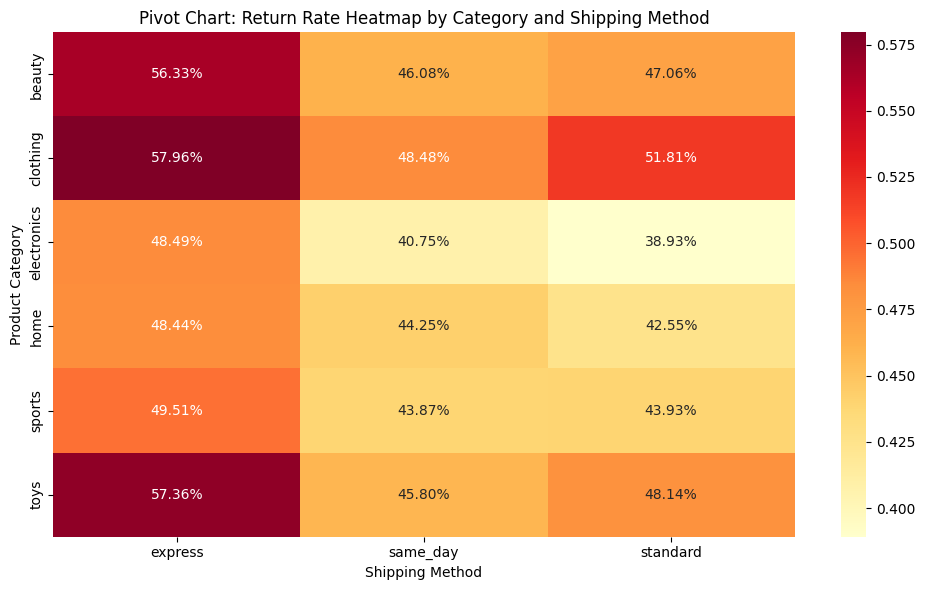

In [13]:
# Pivot Chart 1: Heatmap of Return Rates by Product Category and Shipping Method
plt.figure(figsize=(10, 6))
sns.heatmap(pivot_cat_ship['returned'], annot=True, fmt='.2%', cmap='YlOrRd', cbar=True)
plt.title('Pivot Chart: Return Rate Heatmap by Category and Shipping Method')
plt.ylabel('Product Category')
plt.xlabel('Shipping Method')
plt.tight_layout()
plt.savefig('/content/pivot_chart_category_shipping.png')
plt.show()

<Figure size 1000x500 with 0 Axes>

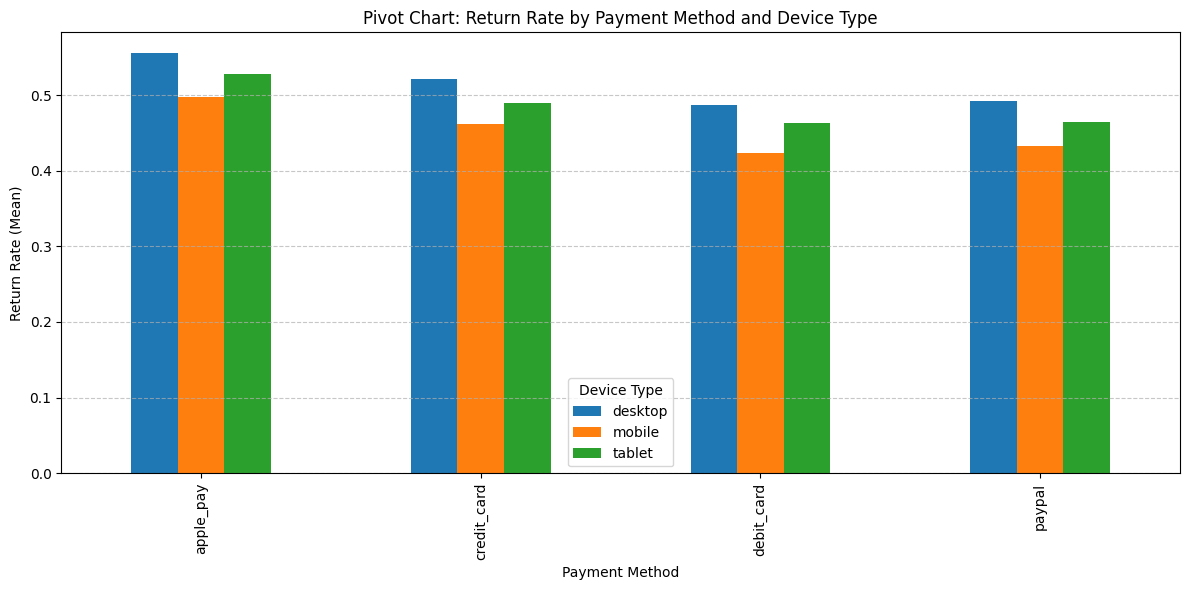

In [14]:
# Pivot Chart 2: Bar Plot of Return Rates by Payment Method
plt.figure(figsize=(10, 5))
pivot_pay_device['mean'].plot(kind='bar', figsize=(12, 6))
plt.title('Pivot Chart: Return Rate by Payment Method and Device Type')
plt.ylabel('Return Rate (Mean)')
plt.xlabel('Payment Method')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Device Type')
plt.tight_layout()
plt.savefig('/content/pivot_chart_payment_device.png')
plt.show()